# MLP_JK_Best — the current best MLP

**Current best:** setup **E** (center + 5×5 neighbor average) on the standard gene list **V_clean**, from **MLP_JK_09_clean_gene_baseline**.

This notebook always holds the MLP setup that currently predicts best. It is replaced only when a new experiment notebook beats it by the rule: highest **validation PCC** (validation patients are training patients, never the test fold), with validation NRMSE no worse than the mean predictor's. Test scores are reported but never used to choose.

**What it does**
- **Genes:** V_clean, built from the rule in `results/standard_gene_rule.json` (per fold, training patients only: no `__ambiguous` bins, expressed in ≥ 10% of training spots, top 50 by variance).
- **Input:** StandardScaler + PCA 256 of the spot's own embedding, and of the average embedding of its 5×5 neighborhood (512 numbers), fit on training spots.
- **MLP:** Linear(512, 128) → ReLU → Dropout 0.3 → Linear(128, 50); Adam lr 3e-4, weight decay 1e-3, batch 256, early stopping (patience 10) on 4 patient-grouped validation groups; shrinkage `k` from 0.2–1.0 chosen on validation NRMSE; 3 final seeds averaged.
- **Baselines:** the mean predictor and ridge ("ridge raw", center PCA 256).
- **Check:** E must reproduce MLP_JK_09's E (test MSE 0.9451, pooled PCC 0.2053, validation PCC 0.2376), and ridge MLP_JK_09's ridge, or the notebook stops.

**History:** the previous Best (the same setup E on the old gene list, which included `__ambiguous` bins) is archived in `archive/MLP_JK_Best_E_old_gene_list/`.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), `~/JHU/BDD/MLP_JK/results/standard_gene_rule.json`, `gene_symbols.csv`, and `MLP_JK_09/`.
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_Best/`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `RULE_FILE`: the standard gene rule (V_clean). `SYMBOLS_FILE`: gene symbols.
- `REFERENCE_DIR`: MLP_JK_09's saved scores; this notebook must reproduce its E and ridge.
- `LOG_RESULTS = False`: the Best notebook doesn't add rows to `all_results.csv` (MLP_JK_09's rows are already there).

**Evaluation, inputs and MLP:** the same as MLP_JK_03/09. The gene list settings come from the rule file.

**Check tolerances:** how far E may be from MLP_JK_09 before the notebook stops (the Apple GPU can differ in the third decimal).

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
RESULTS_DIR = os.path.join(MLP_DIR, "results")
RULE_FILE = os.path.join(RESULTS_DIR, "standard_gene_rule.json")
SYMBOLS_FILE = os.path.join(RESULTS_DIR, "gene_symbols.csv")
REFERENCE_DIR = os.path.join(RESULTS_DIR, "MLP_JK_09")
REFERENCE_NAME = "MLP_JK_09 (logged)"
NOTEBOOK_NAME = "MLP_JK_Best"
LOG_RESULTS = False
OUT_DIR = os.path.join(RESULTS_DIR, NOTEBOOK_NAME)

N_FOLDS = 4
N_INNER_FOLDS = 3
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = {"5x5": 3.0}
N_PCS = 256

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_MSE_TOLERANCE = 0.005
CHECK_PCC_TOLERANCE = 0.01
CHECK_VAL_PCC_TOLERANCE = 0.005
RIDGE_TOLERANCE = 1e-4

The gene rule, the model names, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds.

In [3]:
with open(RULE_FILE) as f:
    gene_rule = json.load(f)
EXCLUDE_PREFIX = gene_rule["exclude_prefix"]
MIN_DETECTION = gene_rule["min_detection"]
N_GENES = gene_rule["n_genes"]
GENE_LIST = gene_rule["name"]
print(f"Gene list {GENE_LIST}: exclude '{EXCLUDE_PREFIX}...', detection >= {MIN_DETECTION}, top {N_GENES} by variance")

MODEL_NAMES = {
    "mean": "mean predictor",
    "ridge": "ridge raw",
    "E": "E 5x5 average",
}
MLP_SETUPS = {"E": "mean_5x5"}

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Gene list V_clean: exclude '__...', detection >= 0.1, top 50 by variance
Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and patient folds (copied from MLP_JK_03)

The 5×5 neighborhood: every spot on the same section within 3.0 spot spacings, including the spot itself. Folds: `GroupKFold` by patient, the same 4 folds as always.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 3. The gene list, V_clean, from the rule file

`standard_genes(train_index)` applies the rule on the fold's training spots: drop the excluded bins, keep genes with count > 0 in at least 10% of the spots, take the top 50 by variance. The lists must equal MLP_JK_09's `standard_genes.csv` in every fold.

In [7]:
symbols = pd.read_csv(SYMBOLS_FILE)
symbol_of = dict(zip(symbols["ensembl_id"], symbols["symbol"]))
is_excluded = np.char.startswith(all_genes.astype(str), EXCLUDE_PREFIX)


def standard_genes(train_index):
    Y_train = Y[train_index]
    detection = np.asarray((Y_train > 0).mean(axis=0)).ravel()
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    variance = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel() - mean ** 2
    candidates = np.where(~is_excluded & (detection >= MIN_DETECTION))[0]
    return candidates[np.argsort(variance[candidates])[::-1][:N_GENES]]


fold_genes = [standard_genes(fold_train_index[fold]) for fold in range(N_FOLDS)]

reference_genes = pd.read_csv(os.path.join(REFERENCE_DIR, "standard_genes.csv"))
for fold in range(N_FOLDS):
    saved = reference_genes[reference_genes["fold"] == fold].sort_values("rank")["ensembl_id"].tolist()
    assert saved == list(all_genes[fold_genes[fold]]), f"fold {fold}: genes differ from MLP_JK_09"
print("V_clean equals MLP_JK_09's standard genes in every fold.")
for fold in range(N_FOLDS):
    print(f"fold {fold}: " + ", ".join(symbol_of[g] for g in all_genes[fold_genes[fold]][:10]) + ", ...")

V_clean equals MLP_JK_09's standard genes in every fold.
fold 0: IGLL5, TFF3, MUC1, RPS3, S100A9, H2AJ, MGP, ERBB2, KRT19, NHERF1, ...
fold 1: TFF3, IGLL5, S100A9, ERBB2, NHERF1, MUC1, COX6C, MGP, KRT19, B2M, ...
fold 2: TFF3, IGLL5, RPS3, ERBB2, KRT19, MUC1, MGP, NHERF1, H2AJ, AZGP1, ...
fold 3: TFF3, IGLL5, RPS3, ERBB2, H2AJ, MUC1, MGP, KRT19, NHERF1, S100A9, ...


## Step 4. Scoring and the error split

**`score_model`** (copied from Notebook 5): per gene, pooled PCC and NRMSE (genes with test SD < 0.05 get no NRMSE), and the same within each test patient.

**`error_parts`** (from MLP_JK_06): a fold's MSE split into **level error** (each test slide's predicted mean vs. its true mean) and **pattern error** (what's left inside each slide). It checks that the two add up to the MSE.

In [8]:
def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def error_parts(result):
    scored = result["y_test"].std(axis=0) >= MIN_TEST_SD
    y_true = result["y_test"][:, scored]
    y_pred = result["y_pred"][:, scored]
    mse = np.mean((y_true - y_pred) ** 2)
    level_error, pattern_error = split_error(y_true, y_pred, result["test_index"])
    assert abs(level_error + pattern_error - mse) < 1e-6, "level + pattern doesn't add up to the MSE"
    return mse, level_error, pattern_error, scored.sum()

## Step 5. PCA inputs for every fold

On each fold's training spots: StandardScaler + PCA 256 of the center embeddings and of the 5×5 averages. E = `center` + `mean_5x5`; ridge uses `center`.

In [9]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
fold_inputs = []
for fold in range(N_FOLDS):
    train_index = fold_train_index[fold]
    fold_inputs.append({"center": pca_256(X_raw, train_index), "mean_5x5": pca_256(X_mean_5x5, train_index)})
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)
del X_raw, X_mean_5x5

fold 0: PCA inputs done (0.2 min)


fold 1: PCA inputs done (0.3 min)


fold 2: PCA inputs done (0.4 min)


fold 3: PCA inputs done (0.5 min)


## Step 6. Ridge, the MLP, and shrinkage (copied from Notebook 5 and MLP_JK_03)

**Ridge:** one alpha per gene, chosen by 3-fold patient-grouped cross-validation inside the training patients.

**The MLP:** input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50). Adam (weight decay 1e-3), MSE loss on standardized genes, batches of 256, early stopping with patience 10 on validation patients. `shrink` = `train_mean + k × (prediction − train_mean)`.

In [10]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred

In [11]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 7. One fold, start to finish

| Step | Uses |
|---|---|
| V_clean, gene means and SDs, ridge alphas | training patients |
| For each of the 4 validation groups | E trained on the fit patients, early stopping on the validation patients |
| `k` | lowest validation NRMSE averaged over the 4 groups |
| Epochs | median best epoch over the 4 groups |
| Final model | E on **all** training patients, 3 seeds, averaged |
| Test patients | used once, for scoring |

The test spots' expression is `NaN` in every array the training reads.

In [12]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def build_input(setup, fold):
    center = fold_inputs[fold]["center"]
    if MLP_SETUPS[setup] is None:
        return center
    return np.concatenate([center, fold_inputs[fold][MLP_SETUPS[setup]]], axis=1)


def run_fold(fold):
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    y_test = Y[test_index][:, gene_index].toarray()
    train_mean = y_fold[train_index].mean(axis=0)
    center = fold_inputs[fold]["center"]

    def as_result(prediction, alpha=no_alpha):
        return {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                "y_pred": prediction, "alpha": alpha}

    test_results = {"mean": as_result(np.tile(train_mean, (len(test_index), 1)))}
    seed_results = {}

    alpha_per_gene = choose_alpha_per_gene(center[train_index], y_fold[train_index], patient_array[train_index])
    ridge_prediction = fit_and_predict(center[train_index], y_fold[train_index], center[test_index], alpha_per_gene)
    test_results["ridge"] = as_result(ridge_prediction, alpha_per_gene)

    val_rows = []
    chosen_rows = []
    for setup in MLP_SETUPS:
        P_device = to_device(build_input(setup, fold))

        for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
            fit_mean = y_fold[fit_rows].mean(axis=0)
            val_result = {
                "fold": fold,
                "test_index": val_index,
                "genes": genes,
                "y_test": y_fold[val_index],
                "y_mean": np.tile(fit_mean, (len(val_index), 1)),
                "alpha": no_alpha,
            }
            mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

            trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
            val_pred = predict(trained, P_device, val_index)
            for k in SHRINK_FACTORS:
                val_result["y_pred"] = shrink(val_pred, fit_mean, k)
                scores, _ = score_model("MLP", [val_result], "y_pred")
                val_rows.append({
                    "setup": setup, "fold": fold, "val_group": group, "k": k,
                    "val_PCC": scores["PCC"].mean(),
                    "val_NRMSE": scores["NRMSE"].mean(),
                    "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                    "best_epoch": trained["best_epoch"],
                })

        val_table = pd.DataFrame(val_rows)
        by_k = val_table[val_table["setup"] == setup].groupby("k").agg(
            val_PCC=("val_PCC", "mean"),
            val_NRMSE=("val_NRMSE", "mean"),
            val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
            epochs=("best_epoch", "median"),
        ).reset_index()
        chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
        chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
        chosen["final_epochs"] = max(1, int(round(chosen["epochs"])))
        chosen.update({"setup": setup, "fold": fold})
        chosen_rows.append(chosen)

        seed_predictions = []
        for seed_number in range(N_FINAL_SEEDS):
            final = train_mlp(P_device, y_fold, train_index, None, chosen["final_epochs"], SEED + seed_number)
            seed_predictions.append(predict(final, P_device, test_index))
        del P_device

        test_results[setup] = as_result(shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]))
        seed_results[setup] = [as_result(shrink(p, train_mean, chosen["k"])) for p in seed_predictions]

    return test_results, seed_results, pd.DataFrame(val_rows), chosen_rows

## Step 8. Run every fold

In [13]:
results = {model: [] for model in MODEL_NAMES}
seed_results = {setup: [[] for _ in range(N_FINAL_SEEDS)] for setup in MLP_SETUPS}
val_tables = []
chosen_rows = []
start_time = time.time()

for fold in range(N_FOLDS):
    fold_results, fold_seed_results, val_table, chosen = run_fold(fold)
    for model in MODEL_NAMES:
        results[model].append(fold_results[model])
    for setup, seed_list in fold_seed_results.items():
        for seed_number, seed_result in enumerate(seed_list):
            seed_results[setup][seed_number].append(seed_result)
    val_tables.append(val_table)
    chosen_rows.extend(chosen)
    ks = ", ".join(f"{c['setup']} k = {c['k']}" for c in chosen)
    print(f"fold {fold} done: {ks}  ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)

fold 0 done: E k = 0.4  (0.2 min)


fold 1 done: E k = 0.4  (0.4 min)


fold 2 done: E k = 0.4  (0.7 min)


fold 3 done: E k = 0.4  (0.9 min)


## Step 9. Results

**Chosen `k` and epochs** per fold (validation patients only). `passes` = validation NRMSE no worse than the mean predictor's.

In [14]:
pd.set_option("display.width", 250)
columns = ["setup", "fold", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings.sort_values(["setup", "fold"])[columns].round(4).to_string(index=False))

setup  fold   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
    E     0 0.4            12   0.2982     1.0978                    1.1441    True
    E     1 0.4            12   0.1907     1.1077                    1.1268    True
    E     2 0.4            18   0.2108     1.0601                    1.0978    True
    E     3 0.4            10   0.2506     1.0560                    1.0825    True


**Scores.** Test MSE, level and pattern error are averaged over all scored genes; PCC, NRMSE and within-patient PCC over all genes (and patients). **Seed spread** = the range of each score over the 3 final seeds.

In [15]:
def score_results(fold_results, model_name):
    pooled, within = score_model(model_name, fold_results, "y_pred")
    rows = []
    for r in fold_results:
        mse, level_error, pattern_error, n_scored = error_parts(r)
        fold = r["fold"]
        rows.append({
            "model": model_name, "fold": fold, "MSE": mse, "level_error": level_error,
            "pattern_error": pattern_error, "genes_scored": n_scored,
            "PCC": pooled.loc[pooled["fold"] == fold, "PCC"].mean(),
            "NRMSE": pooled.loc[pooled["fold"] == fold, "NRMSE"].mean(),
            "PCC_within": within.loc[within["fold"] == fold, "PCC_within"].mean(),
        })
    folds = pd.DataFrame(rows)
    folds["level_share"] = folds["level_error"] / folds["MSE"]
    n = folds["genes_scored"]
    overall = {
        "test_MSE": np.sum(folds["MSE"] * n) / n.sum(),
        "pooled_PCC": pooled["PCC"].mean(),
        "within_PCC": within["PCC_within"].mean(),
        "NRMSE": pooled["NRMSE"].mean(),
        "level_error": np.sum(folds["level_error"] * n) / n.sum(),
        "pattern_error": np.sum(folds["pattern_error"] * n) / n.sum(),
    }
    overall["level_share"] = overall["level_error"] / overall["test_MSE"]
    return folds, overall, pooled, within


summary_rows = []
fold_tables = []
pooled_tables = []
within_tables = []
for model, model_name in MODEL_NAMES.items():
    folds, overall, pooled_part, within_part = score_results(results[model], model_name)
    row = {"gene_list": GENE_LIST, "model": model_name}
    row.update(overall)
    if model in MLP_SETUPS:
        c = chosen_settings[chosen_settings["setup"] == model].sort_values("fold")
        row["val_PCC"] = c["val_PCC"].mean()
        row["val_NRMSE"] = c["val_NRMSE"].mean()
        row["val_mean_predictor_NRMSE"] = c["val_mean_predictor_NRMSE"].mean()
        row["chosen_k"] = "/".join(str(k) for k in c["k"])
    if model == "O":
        row["chosen_k"] = "same as D"
    if model in seed_results:
        seed_overall = [score_results(seed_results[model][s], "seed")[1] for s in range(N_FINAL_SEEDS)]
        for metric in ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE"]:
            values = [o[metric] for o in seed_overall]
            row[f"seed_range_{metric}"] = max(values) - min(values)
    summary_rows.append(row)
    fold_tables.append(folds)
    pooled_tables.append(pooled_part)
    within_tables.append(within_part)

summary = pd.DataFrame(summary_rows)
fold_scores = pd.concat(fold_tables, ignore_index=True)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)
assert np.allclose(summary["level_error"] + summary["pattern_error"], summary["test_MSE"]), "split doesn't add up"
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

summary_columns = ["model", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "chosen_k",
                   "level_error", "pattern_error", "level_share"]
print(summary[summary_columns].round(4).to_string(index=False))
print("\nSeed spread (max - min over the 3 seeds):")
print(summary.dropna(subset=["seed_range_test_MSE"])[["model"] + [c for c in summary.columns if c.startswith("seed_range")]]
      .round(4).to_string(index=False))
print("\nLevel and pattern error add up to the test MSE in every fold, for every model.")

print()
for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC"), ("NRMSE", "NRMSE"), ("PCC_within", "Within-patient PCC"),
                      ("level_share", "Level share")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(list(MODEL_NAMES.values())).round(4).to_string())
    print()

         model  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k  level_error  pattern_error  level_share
mean predictor    0.9987         NaN         NaN 1.0980      NaN        NaN             NaN       0.5917         0.4070       0.5925
     ridge raw    0.9674      0.1945      0.1573 1.0863      NaN        NaN             NaN       0.5517         0.4157       0.5703
 E 5x5 average    0.9451      0.2053      0.1731 1.0673   0.2376     1.0804 0.4/0.4/0.4/0.4       0.5550         0.3901       0.5873

Seed spread (max - min over the 3 seeds):
        model  seed_range_test_MSE  seed_range_pooled_PCC  seed_range_within_PCC  seed_range_NRMSE
E 5x5 average               0.0025                 0.0136                 0.0095            0.0029

Level and pattern error add up to the test MSE in every fold, for every model.

Test MSE per fold:
fold                 0       1       2       3
model                                         
mean predictor  1.0409  1.1096  0

## Step 10. Check against MLP_JK_09

This notebook repeats MLP_JK_09's setup E (same genes, inputs, settings and seeds), so its numbers must match: test MSE within 0.005, pooled PCC within 0.01, validation PCC within 0.005. Ridge has no randomness, so it must match to 4 decimals. Otherwise the notebook stops.

The saved MLP_JK_09 run is added to the summary as a reference row (`MLP_JK_09 (logged)`).

In [16]:
reference = pd.read_csv(os.path.join(REFERENCE_DIR, "summary.csv")).set_index("model")
ours = summary.set_index("model")

check_rows = []
for model_name, metric, tolerance in [
        ("E 5x5 average", "test_MSE", CHECK_MSE_TOLERANCE),
        ("E 5x5 average", "pooled_PCC", CHECK_PCC_TOLERANCE),
        ("E 5x5 average", "val_PCC", CHECK_VAL_PCC_TOLERANCE),
        ("E 5x5 average", "within_PCC", CHECK_PCC_TOLERANCE),
        ("E 5x5 average", "NRMSE", CHECK_MSE_TOLERANCE),
        ("ridge raw", "test_MSE", RIDGE_TOLERANCE),
        ("ridge raw", "pooled_PCC", RIDGE_TOLERANCE),
        ("mean predictor", "test_MSE", RIDGE_TOLERANCE)]:
    here = ours.loc[model_name, metric]
    saved = reference.loc[model_name, metric]
    check_rows.append({"model": model_name, "metric": metric, "this_notebook": here, "MLP_JK_09": saved,
                       "difference": here - saved, "tolerance": tolerance, "ok": abs(here - saved) <= tolerance})
reproduction_check = pd.DataFrame(check_rows)
print(reproduction_check.round(4).to_string(index=False))
assert reproduction_check["ok"].all(), "The Best doesn't reproduce MLP_JK_09. Stop and check before going further."
print("\nMLP_JK_Best reproduces MLP_JK_09's E and ridge.")

reference_row = reference.loc["E 5x5 average"].to_dict()
reference_row["model"] = REFERENCE_NAME
summary = pd.concat([summary.iloc[:2], pd.DataFrame([reference_row])[summary.columns], summary.iloc[2:]], ignore_index=True)

         model     metric  this_notebook  MLP_JK_09  difference  tolerance   ok
 E 5x5 average   test_MSE         0.9451     0.9451        -0.0     0.0050 True
 E 5x5 average pooled_PCC         0.2053     0.2053         0.0     0.0100 True
 E 5x5 average    val_PCC         0.2376     0.2376         0.0     0.0050 True
 E 5x5 average within_PCC         0.1731     0.1731         0.0     0.0100 True
 E 5x5 average      NRMSE         1.0673     1.0673         0.0     0.0050 True
     ridge raw   test_MSE         0.9674     0.9674         0.0     0.0001 True
     ridge raw pooled_PCC         0.1945     0.1945         0.0     0.0001 True
mean predictor   test_MSE         0.9987     0.9987         0.0     0.0001 True

MLP_JK_Best reproduces MLP_JK_09's E and ridge.


## Step 11. Plots

**Figure 1:** test MSE and pooled PCC per model. Bars = average over folds, dots = the 4 folds, black line = the range over the 3 seeds; red dashed line = the mean predictor's MSE.

**Figure 2:** test MSE split into level error (each slide's mean off) and pattern error (inside each slide), as in MLP_JK_06.

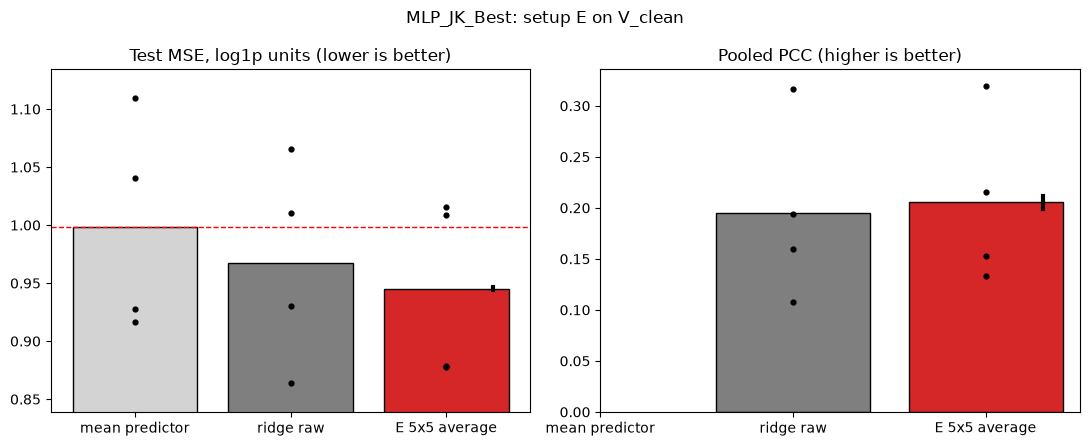

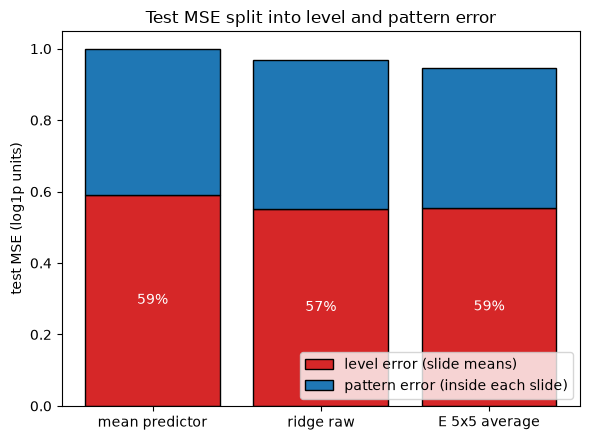

In [17]:
colors = {"mean predictor": "lightgrey", "ridge raw": "tab:gray", "E 5x5 average": "tab:red"}
plot_models = list(colors)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, column, summary_column, seed_column, title in [
        (axes[0], "MSE", "test_MSE", "seed_range_test_MSE", "Test MSE, log1p units (lower is better)"),
        (axes[1], "PCC", "pooled_PCC", "seed_range_pooled_PCC", "Pooled PCC (higher is better)")]:
    for i, model_name in enumerate(plot_models):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        row = summary[summary["model"] == model_name].iloc[0]
        if pd.notna(row.get(seed_column)):
            half = row[seed_column] / 2
            ax.plot([i + 0.3, i + 0.3], [row[summary_column] - half, row[summary_column] + half], color="black", linewidth=3)
    ax.set_xticks(range(len(plot_models)))
    ax.set_xticklabels(plot_models)
    ax.set_title(title)
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores["MSE"].min()
high = fold_scores["MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
fig.suptitle(f"MLP_JK_Best: setup E on {GENE_LIST}")
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
rows = summary.set_index("model").loc[plot_models]
x = np.arange(len(plot_models))
ax.bar(x, rows["level_error"], color="tab:red", edgecolor="black", label="level error (slide means)")
ax.bar(x, rows["pattern_error"], bottom=rows["level_error"], color="tab:blue", edgecolor="black",
       label="pattern error (inside each slide)")
for i, model_name in enumerate(plot_models):
    ax.text(i, rows.loc[model_name, "level_error"] / 2, f"{rows.loc[model_name, 'level_share']:.0%}",
            ha="center", va="center", color="white")
ax.set_xticks(x)
ax.set_xticklabels(plot_models)
ax.set_ylabel("test MSE (log1p units)")
ax.set_title("Test MSE split into level and pattern error")
ax.legend(loc="lower right")
plt.tight_layout()
save_figure("2_error_split.png")
plt.show()

## Step 12. Save results

Later notebooks read `summary.csv` for the Best's validation PCC (the `E 5x5 average` row; the `MLP_JK_09 (logged)` row is only the reference). This notebook does not add rows to `all_results.csv`.

In [18]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
reproduction_check.to_csv(os.path.join(OUT_DIR, "reproduction_check.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
pd.DataFrame([{"fold": fold, "rank": rank, "ensembl_id": gene, "symbol": symbol_of[gene]}
              for fold in range(N_FOLDS) for rank, gene in enumerate(all_genes[fold_genes[fold]])]
             ).to_csv(os.path.join(OUT_DIR, "genes.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "best_setup": "E 5x5 average",
    "from_notebook": "MLP_JK_09_clean_gene_baseline",
    "gene_rule": gene_rule,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

print(summary[["model", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "chosen_k",
               "level_share"]].round(4).to_string(index=False))
print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

             model  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k  level_share
    mean predictor    0.9987         NaN         NaN 1.0980      NaN        NaN             NaN       0.5925
         ridge raw    0.9674      0.1945      0.1573 1.0863      NaN        NaN             NaN       0.5703
MLP_JK_09 (logged)    0.9451      0.2053      0.1731 1.0673   0.2376     1.0804 0.4/0.4/0.4/0.4       0.5873
     E 5x5 average    0.9451      0.2053      0.1731 1.0673   0.2376     1.0804 0.4/0.4/0.4/0.4       0.5873

Saved to /Users/jk/JHU/BDD/MLP_JK/results/MLP_JK_Best
   1_mse_and_pcc.png
   2_error_split.png
   chosen_settings.csv
   fold_scores.csv
   genes.csv
   pooled_gene_scores.csv
   reproduction_check.csv
   settings.json
   summary.csv
   validation_scores.csv
   within_patient_gene_scores.csv


## Summary in plain words

**What changed:** the Best is the same model as before (setup E: the spot's own embedding plus the average of its 5×5 neighborhood), now trained and scored on the cleaned standard gene list **V_clean** (no `__ambiguous` read bins). The previous Best, on the old list, is archived in `archive/MLP_JK_Best_E_old_gene_list/`.

**Reproduction:** every number matches MLP_JK_09's E exactly (test MSE 0.9451, pooled PCC 0.2053, validation PCC 0.2376, the same `k` = 0.4 in every fold), ridge matches too, and the gene lists equal MLP_JK_09's in every fold.

| Score | What it means | Good vs. bad | Mean predictor | Ridge | **Best (E)** |
|---|---|---|---|---|---|
| **Test MSE** | Average squared error of log1p expression | Lower is better | 0.9987 | 0.9674 | **0.9451** |
| **Pooled PCC** | Correlation over all test spots | Higher is better; 0 = no relation | – | 0.1945 | **0.2053** |
| **Within-patient PCC** | Correlation inside each patient | Higher is better | – | 0.1573 | **0.1731** |
| **NRMSE** | Error ÷ the gene's spread | Lower is better; below the mean predictor = better than guessing | 1.0980 | 1.0863 | **1.0673** |
| **Validation PCC** | PCC on held-out training patients; used for choosing | Higher is better | – | – | **0.2376** |
| **Validation NRMSE** | The same for NRMSE | Must be ≤ the mean predictor's (1.1128) | – | – | **1.0804** |
| **Level share** | Fraction of the MSE from whole slides being shifted | Lower = less slide-level error | 59.3% | 57.0% | 58.7% |

**To beat it**, a new setup needs a validation PCC above **0.2376** on V_clean, with validation NRMSE no worse than the mean predictor's.